# Exercise 62 – Graph neural networks for cluster energies

**Week 13 · Graph neural networks**

Small 6-atom clusters are turned into graphs (atoms closer than 2.5 are
connected, all node attributes start at 1). A GNN stacks message-passing
layers to build a *representation* of every atom, reads out one number per
atom – a **local energy** – and sums them to get the total energy:

$$E = \sum_i \varepsilon_i, \qquad \varepsilon_i = \text{GNN}(\text{graph})_i$$

Three datasets are used, generated with increasingly complicated energy
models: a nearest/next-nearest-neighbour count model, a tight-binding model,
and a modified tight-binding model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_add_pool

from comphy import DATA_DIR
from comphy.graphs import PhiPsiConv, edges_within_cutoff, plot_graph
from comphy.plotting import parity_plot
from comphy.training import evaluate, predict, train

torch.manual_seed(0)
DATASETS = {"nn-nnn": "nn_nnn_clusters_6.npz", "tight binding": "tight_binding_clusters_6.npz",
            "modified tight binding": "modified_tb_clusters_6.npz"}


def load_graphs(filename, cutoff=2.5):
    data = np.load(DATA_DIR / "exercise_62" / filename)
    graphs = []
    for pos, energy in zip(data["positions"], data["energies"]):
        pos = torch.tensor(pos, dtype=torch.float32)
        graphs.append(Data(x=torch.ones(len(pos), 1), pos=pos,
                           edge_index=edges_within_cutoff(pos, cutoff),
                           y=torch.tensor(float(energy))))
    return graphs


graphs = load_graphs(DATASETS["nn-nnn"])
print(f"{len(graphs)} graphs, e.g. {graphs[0]}")

44 graphs, e.g. Data(x=[6, 1], edge_index=[2, 18], y=-22.200000762939453, pos=[6, 2])


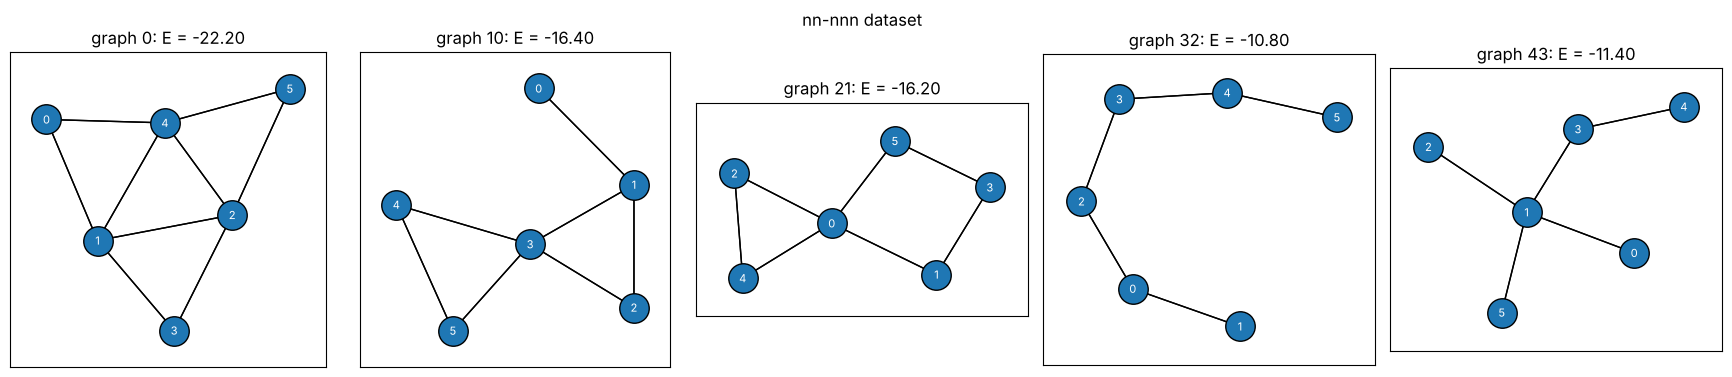

In [2]:
def show_graphs(graphs, values=None, title=None, ncols=5):
    fig, axes = plt.subplots(1, ncols, figsize=(3.5 * ncols, 3.8))
    for ax, i in zip(axes, np.linspace(0, len(graphs) - 1, ncols).astype(int)):
        g = graphs[i]
        vals = None if values is None else values(g)
        plot_graph(ax, g, values=vals, size=450, cmap="coolwarm", fmt="{:.2f}", fontsize=8,
                   title=f"graph {i}: E = {g.y.item():.2f}")
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_graphs(graphs, title="nn-nnn dataset")

## The model

`EnergyGNN(dims)` stacks `PhiPsiConv` layers with the given feature
dimensions, e.g. `dims=(1, 1, 1)` is two layers that keep one number per node.

In [3]:
class EnergyGNN(nn.Module):
    def __init__(self, dims=(1, 1), d_message=None, activation=None):
        super().__init__()
        self.layers = nn.ModuleList(PhiPsiConv(a, b, d_message=d_message)
                                    for a, b in zip(dims[:-1], dims[1:]))
        self.activation = activation

    def local_energies(self, data):
        x = data.x
        for i, layer in enumerate(self.layers):
            x = layer(x, data.edge_index)
            if self.activation is not None and i < len(self.layers) - 1:
                x = self.activation(x)
        return x

    def forward(self, data):
        batch = data.batch if data.batch is not None else torch.zeros(data.num_nodes, dtype=torch.long)
        return global_add_pool(self.local_energies(data), batch).flatten()


def local_energy_values(model):
    def values(g):
        with torch.no_grad():
            return model.local_energies(g)
    return values

## One and two message-passing layers on the nn-nnn dataset

Early stopping on the training loss (patience 70).

In [4]:
loader = DataLoader(graphs, batch_size=2, shuffle=True)
eval_loader = DataLoader(graphs, batch_size=44)
models = {"1 layer": EnergyGNN(dims=(1, 1)), "2 layers": EnergyGNN(dims=(1, 1, 1))}
histories = {}
for name, model in models.items():
    torch.manual_seed(0)
    histories[name] = train(model, loader, epochs=1000, lr=0.01, patience=70, restore_best=True)
    print(f"{name}: MSE {evaluate(model, eval_loader):.4g}")

Early stopping at epoch 234
1 layer: MSE 0.1446


Early stopping at epoch 377
2 layers: MSE 1.172e-07


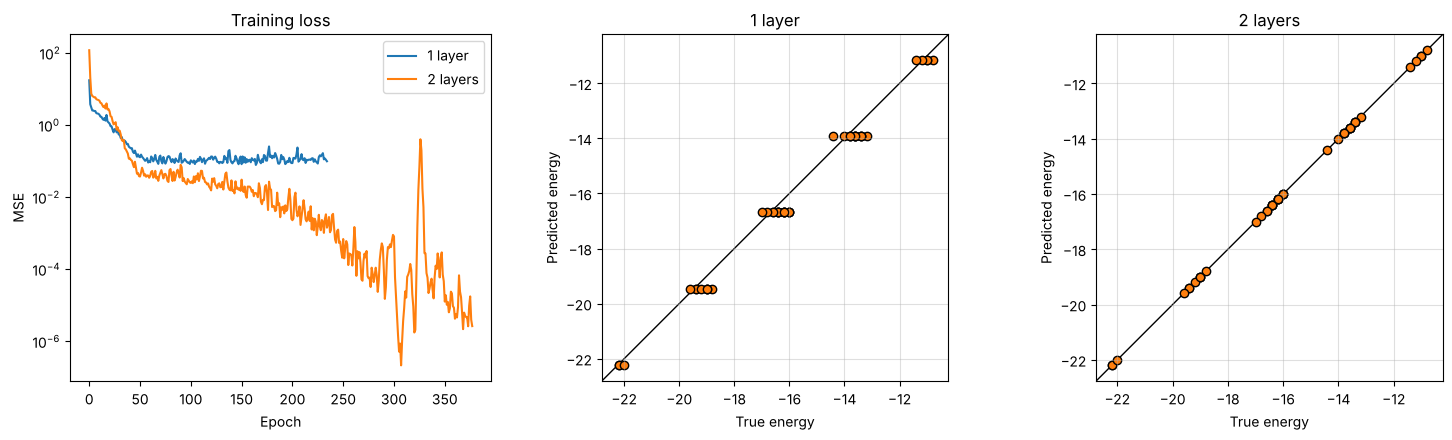

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for name, h in histories.items():
    axes[0].plot(h["train"], label=name)
axes[0].set(xlabel="Epoch", ylabel="MSE", yscale="log", title="Training loss")
axes[0].legend()
for ax, (name, model) in zip(axes[1:], models.items()):
    parity_plot(ax, *predict(model, eval_loader), color="C1", edgecolor="black")
    ax.set_title(name)
fig.tight_layout()
plt.show()

A single layer only sees nearest neighbours. Two layers also reach the
next-nearest neighbours, which this energy model depends on, and the fit
becomes essentially exact. The learned local energies:

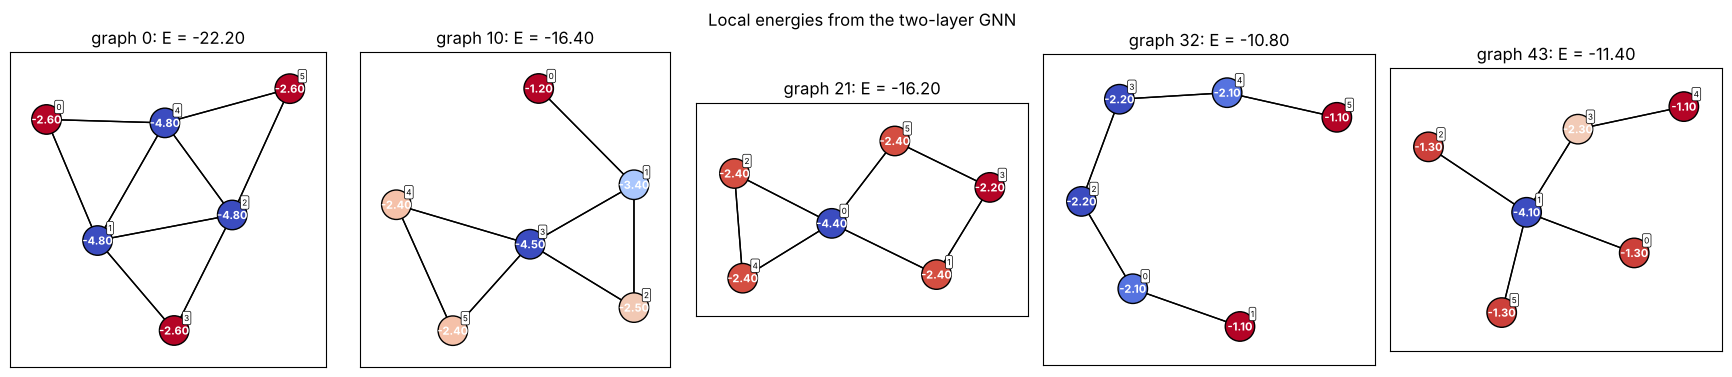

In [6]:
show_graphs(graphs, values=local_energy_values(models["2 layers"]),
            title="Local energies from the two-layer GNN")

## Tight-binding datasets

Nine fixed graphs are held out as a test set. We compare

* two layers with one feature per node,
* four layers with four features per node,
* four layers with 32 features per node and SiLU activations.

In [7]:
test_indices = [23, 36, 21, 19, 9, 39, 42, 3, 0]
architectures = {
    "2 layers, width 1": dict(dims=(1, 1, 1), lr=0.01, epochs=2000, patience=30),
    "4 layers, width 4": dict(dims=(1, 4, 4, 4, 1), d_message=4, lr=0.01, epochs=2000, patience=100),
    "4 layers, width 32, SiLU": dict(dims=(1, 32, 32, 32, 1), d_message=32, activation=nn.SiLU(),
                                     lr=1e-3, epochs=3000, patience=500),
}

results = {}
for dataset in ["tight binding", "modified tight binding"]:
    all_graphs = load_graphs(DATASETS[dataset])
    test_graphs = [all_graphs[i] for i in test_indices]
    train_graphs = [g for i, g in enumerate(all_graphs) if i not in test_indices]
    train_loader = DataLoader(train_graphs, batch_size=4, shuffle=True)
    test_loader = DataLoader(test_graphs, batch_size=9)
    for name, cfg in architectures.items():
        cfg = dict(cfg)
        lr, epochs, patience = cfg.pop("lr"), cfg.pop("epochs"), cfg.pop("patience")
        torch.manual_seed(0)
        model = EnergyGNN(**cfg)
        print(f"{dataset} / {name}")
        train(model, train_loader, epochs=epochs, lr=lr, patience=patience, restore_best=True)
        results[dataset, name] = dict(model=model, test_graphs=test_graphs,
                                      train=predict(model, DataLoader(train_graphs, batch_size=64)),
                                      test=predict(model, test_loader),
                                      test_mse=evaluate(model, test_loader))

tight binding / 2 layers, width 1


Early stopping at epoch 97
tight binding / 4 layers, width 4


Early stopping at epoch 189
tight binding / 4 layers, width 32, SiLU


modified tight binding / 2 layers, width 1


Early stopping at epoch 88
modified tight binding / 4 layers, width 4


Early stopping at epoch 341
modified tight binding / 4 layers, width 32, SiLU


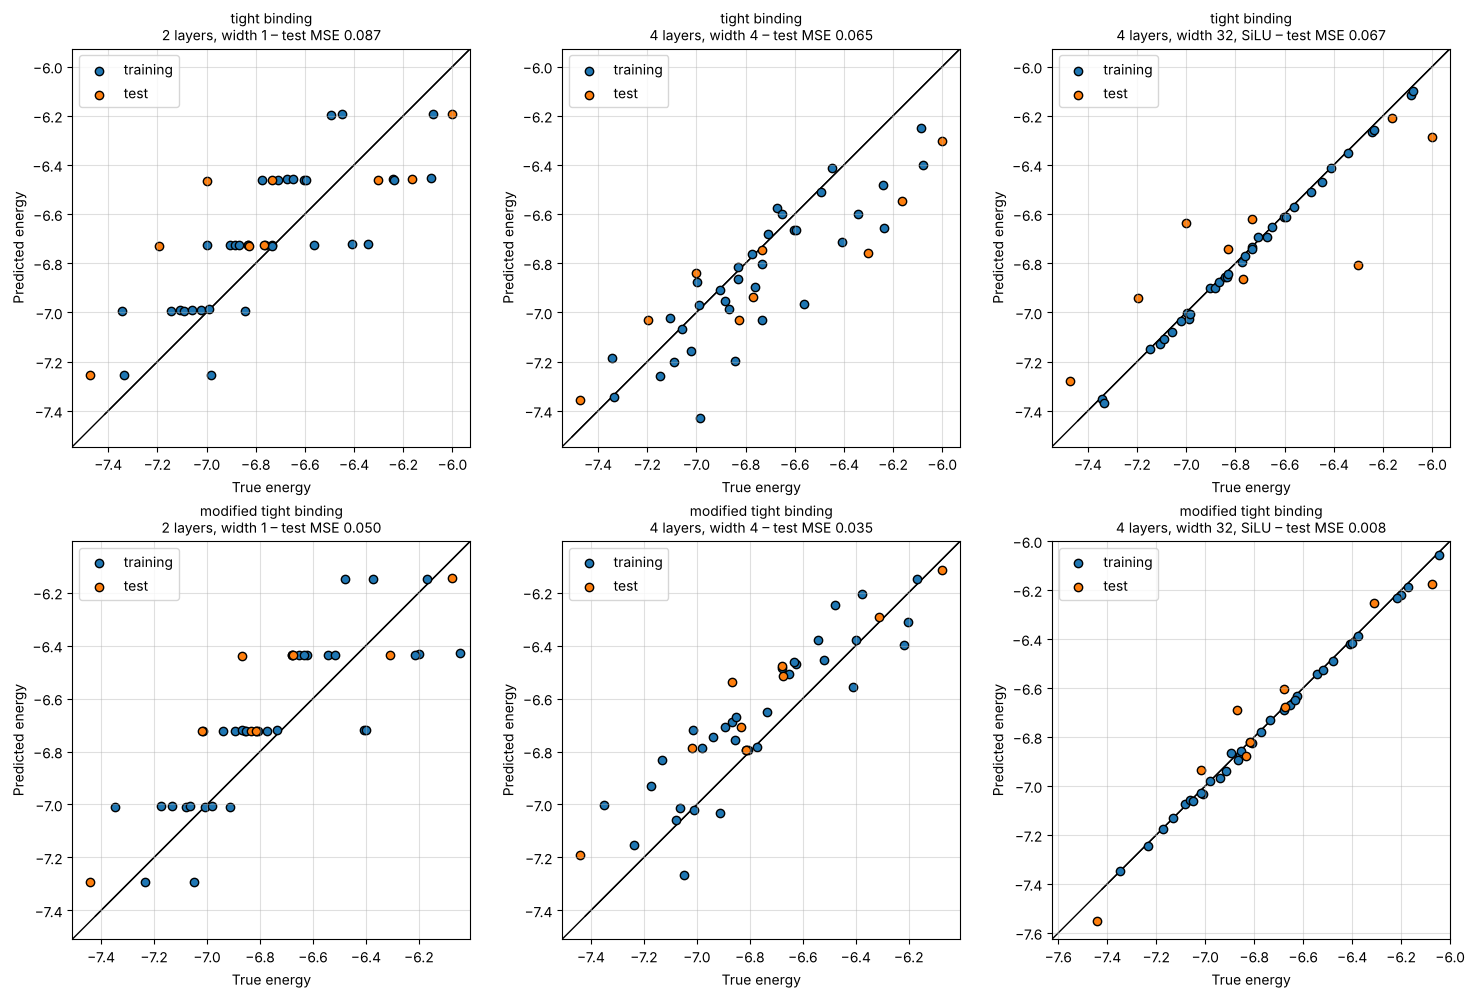

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, ((dataset, name), res) in zip(axes.flat, results.items()):
    parity_plot(ax, *res["train"], label="training", edgecolor="black")
    parity_plot(ax, *res["test"], label="test", color="C1", edgecolor="black")
    ax.set_title(f"{dataset}\n{name} – test MSE {res['test_mse']:.3f}", fontsize=10)
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Local energies of the test clusters from the widest model on the tight-binding data:

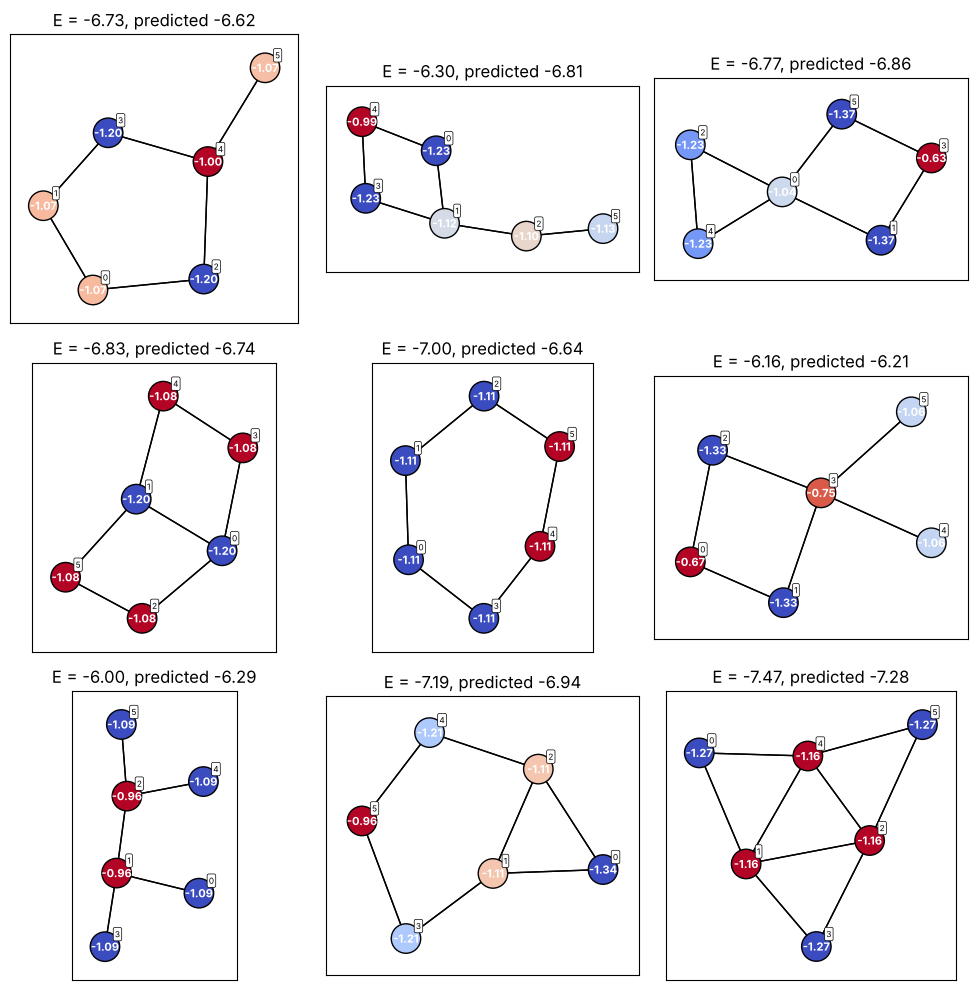

In [9]:
res = results["tight binding", "4 layers, width 32, SiLU"]
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, g in zip(axes.flat, res["test_graphs"]):
    with torch.no_grad():
        eps = res["model"].local_energies(g)
    plot_graph(ax, g, values=eps, size=450, cmap="coolwarm", fmt="{:.2f}", fontsize=8,
               title=f"E = {g.y.item():.2f}, predicted {eps.sum().item():.2f}")
fig.tight_layout()
plt.show()